In [ ]:

# Step 1: Check our Python environment and import libraries

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nEnvironment ready for the Flood Early-Warning System!")



Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

Environment ready for the Flood Early-Warning System!


In [ ]:

# Step 2: Inspect the public GitHub repository
# to locate the dataset and its download instructions.

import requests

repo_url = "https://api.github.com/repos/ruthnavarro22/flood-prediction-ml/contents"

response = requests.get(repo_url, timeout=30)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    files = response.json()
    print("\nFiles and folders in the repository:\n")

    for item in files:
        print(f"{item['type']:5} | {item['name']}")

else:
    print("Could not access the repository.")
    print(response.text[:500])


HTTP status: 200

Files and folders in the repository:

file  | README.md
dir   | data
dir   | images
dir   | notebooks
file  | requirements.txt


In [ ]:

import requests

data_url = (
    "https://api.github.com/repos/"
    "ruthnavarro22/flood-prediction-ml/contents/data"
)

response = requests.get(data_url, timeout=30)
print("HTTP status:", response.status_code)

if response.status_code == 200:
    for item in response.json():
        print(item["type"], "|", item["name"], "|", item["download_url"])
else:
    print(response.text[:500])


HTTP status: 200
file | README.md | https://raw.githubusercontent.com/ruthnavarro22/flood-prediction-ml/main/data/README.md


In [ ]:

# Step 5: Extract the downloaded dataset

import zipfile
from pathlib import Path

zip_path = Path("/content/archive.zip")
extract_path = Path("/content/flood_dataset")

if zip_path.exists():
    extract_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("ZIP extracted successfully!")
    print("\nFiles found:")

    for file in extract_path.rglob("*"):
        if file.is_file():
            print(file.relative_to(extract_path))
else:
    print("archive.zip was not found. Please check the Files panel.")


ZIP extracted successfully!

Files found:
Flood_Prediction_NCR_Philippines.csv


In [ ]:

# Step 6: Load and inspect the flood dataset

from pathlib import Path
import pandas as pd

csv_path = Path(
    "/content/flood_dataset/Flood_Prediction_NCR_Philippines.csv"
)

df = pd.read_csv(csv_path)

print("DATASET OVERVIEW")
print("=" * 50)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nFIRST FIVE ROWS")
display(df.head())

print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nPOSSIBLE FLOOD LABELS")
for col in df.columns:
    if any(word in col.lower() for word in ["flood", "occurrence", "risk"]):
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))


DATASET OVERVIEW
Number of rows: 7308
Number of columns: 7

COLUMN NAMES
['Date', 'Location', 'Rainfall_mm', 'WaterLevel_m', 'SoilMoisture_pct', 'Elevation_m', 'FloodOccurrence']

FIRST FIVE ROWS


,Date,Location,Rainfall_mm,WaterLevel_m,SoilMoisture_pct,Elevation_m,FloodOccurrence
0,2016-01-01,Quezon City,12.0,0.5,15.3,43,0
1,2016-01-01,Marikina,10.6,1.8,23.2,15,0
2,2016-01-01,Manila,5.7,0.5,15.6,5,0
3,2016-01-01,Pasig,3.7,0.5,5.0,5,0
4,2016-01-02,Quezon City,3.4,0.5,13.3,43,0



DATA TYPES
Date                 object
Location             object
Rainfall_mm         float64
WaterLevel_m        float64
SoilMoisture_pct    float64
Elevation_m           int64
FloodOccurrence       int64
dtype: object

MISSING VALUES
Date                0
Location            0
Rainfall_mm         0
WaterLevel_m        0
SoilMoisture_pct    0
Elevation_m         0
FloodOccurrence     0
dtype: int64

DUPLICATE ROWS
0

POSSIBLE FLOOD LABELS

FloodOccurrence:
FloodOccurrence
0    7176
1     132
Name: count, dtype: int64


In [ ]:

# Step 7: Detailed data quality inspection

print("ALL COLUMN NAMES:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nDATASET INFORMATION:")
df.info()

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nNUMERICAL SUMMARY:")
display(df.describe())

# Inspect the flood target column
target_candidates = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["flood", "occurrence", "risk"])
]

print("\nPOSSIBLE FLOOD TARGET COLUMNS:")
print(target_candidates)

for col in target_candidates:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts(dropna=False))


ALL COLUMN NAMES:
1. Date
2. Location
3. Rainfall_mm
4. WaterLevel_m
5. SoilMoisture_pct
6. Elevation_m
7. FloodOccurrence

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7308 entries, 0 to 7307
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              7308 non-null   object 
 1   Location          7308 non-null   object 
 2   Rainfall_mm       7308 non-null   float64
 3   WaterLevel_m      7308 non-null   float64
 4   SoilMoisture_pct  7308 non-null   float64
 5   Elevation_m       7308 non-null   int64  
 6   FloodOccurrence   7308 non-null   int64  
dtypes: float64(3), int64(2), object(2)
memory usage: 399.8+ KB

MISSING VALUES:
Date                0
Location            0
Rainfall_mm         0
WaterLevel_m        0
SoilMoisture_pct    0
Elevation_m         0
FloodOccurrence     0
dtype: int64

DUPLICATE ROWS:
0

NUMERICAL SUMMARY:


,Rainfall_mm,WaterLevel_m,SoilMoisture_pct,Elevation_m,FloodOccurrence
count,7308.000000,7308.000000,7308.000000,7308.000000,7308.000000
mean,10.052874,1.266379,15.184989,17.000000,0.018062
std,7.101769,0.902239,5.994044,15.557414,0.133186
min,0.100000,0.500000,5.000000,5.000000,0.000000
25%,4.900000,0.500000,10.900000,5.000000,0.000000
50%,8.400000,1.000000,14.900000,10.000000,0.000000
75%,13.500000,1.800000,19.100000,22.000000,0.000000
max,52.700000,6.400000,39.700000,43.000000,1.000000



POSSIBLE FLOOD TARGET COLUMNS:
['FloodOccurrence']

Value counts for FloodOccurrence:
FloodOccurrence
0    7176
1     132
Name: count, dtype: int64


In [ ]:

# Step 8: Check flood-label distribution and duplicates

print("FloodOccurrence value counts:")
print(df["FloodOccurrence"].value_counts().sort_index())

print("\nFloodOccurrence percentages:")
print(
    (df["FloodOccurrence"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique locations:")
print(df["Location"].nunique())
print(df["Location"].value_counts())

print("\nFlood label values:")
print(sorted(df["FloodOccurrence"].unique()))


FloodOccurrence value counts:
FloodOccurrence
0    7176
1     132
Name: count, dtype: int64

FloodOccurrence percentages:
FloodOccurrence
0    98.19
1     1.81
Name: proportion, dtype: float64

Duplicate rows: 0

Unique locations:
4
Location
Quezon City    1827
Marikina       1827
Manila         1827
Pasig          1827
Name: count, dtype: int64

Flood label values:
[np.int64(0), np.int64(1)]


Rows before cleaning: 7308
Rows after cleaning: 7308
Rows removed: 0

Missing values after cleaning:
Date                0
Location            0
Rainfall_mm         0
WaterLevel_m        0
SoilMoisture_pct    0
FloodOccurrence     0
dtype: int64

Flood-label distribution after cleaning:
FloodOccurrence
0    7176
1     132
Name: count, dtype: int64


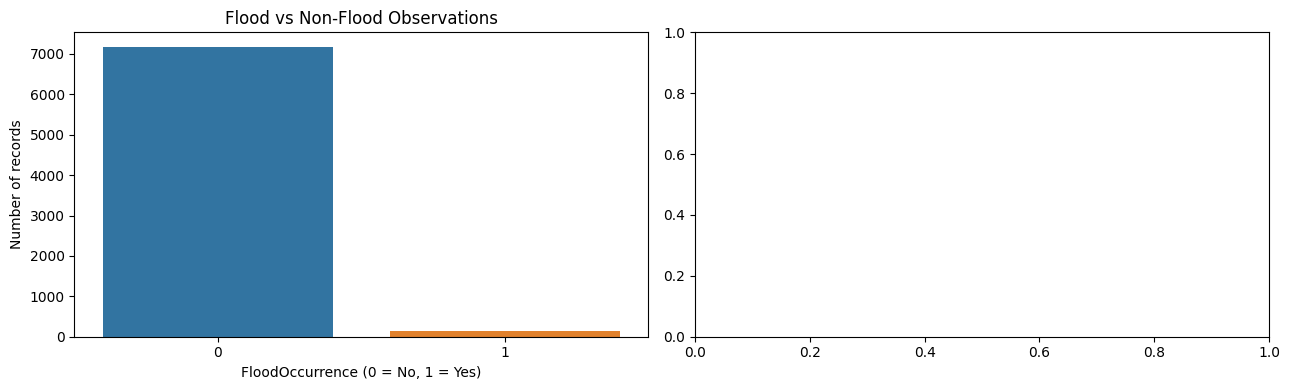

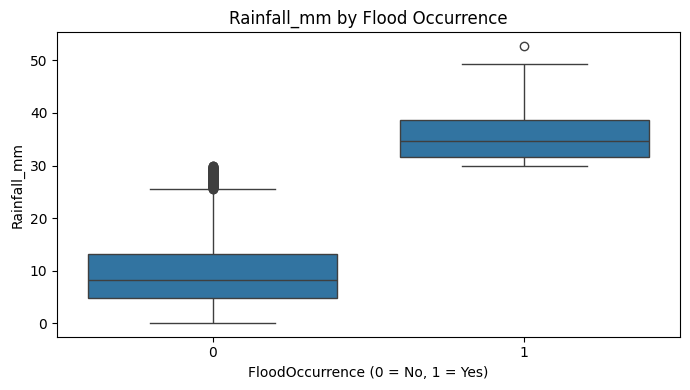

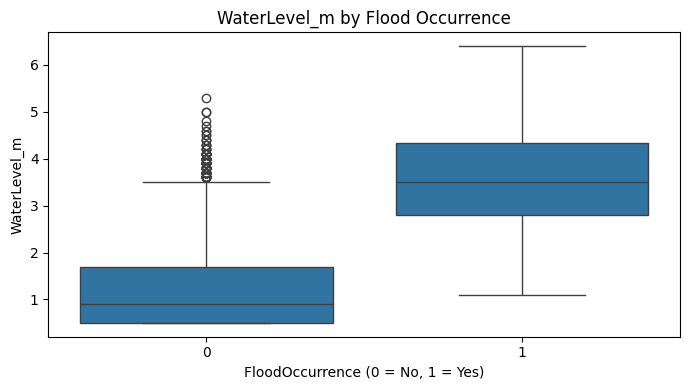

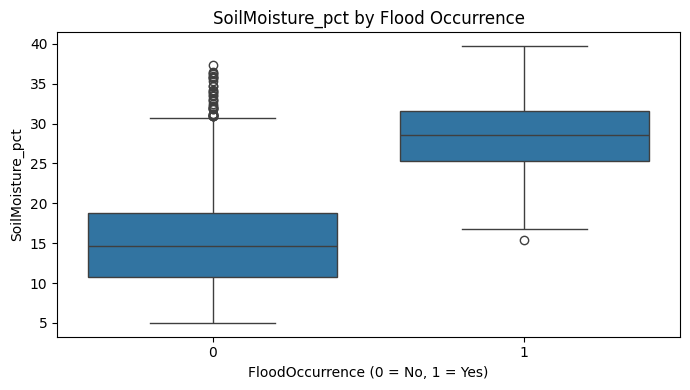

In [ ]:

# Step 9: Data cleaning and exploratory data analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# Keep the original dataset unchanged
df_clean = df.copy()

# Convert date and numeric columns to the correct data types
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce"
)

numeric_cols = [
    "Rainfall_mm",
    "WaterLevel_m",
    "SoilMoisture_pct",
    "Elevation_m",
    "FloodOccurrence"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Remove rows with invalid values in required columns
required_cols = [
    "Date", "Location", "Rainfall_mm",
    "WaterLevel_m", "SoilMoisture_pct",
    "FloodOccurrence"
]

before = len(df_clean)
df_clean = df_clean.dropna(subset=required_cols).copy()

# Validate the binary target
df_clean = df_clean[
    df_clean["FloodOccurrence"].isin([0, 1])
].copy()

print("Rows before cleaning:", before)
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", before - len(df_clean))
print("\nMissing values after cleaning:")
print(df_clean[required_cols].isnull().sum())

print("\nFlood-label distribution after cleaning:")
print(df_clean["FloodOccurrence"].value_counts())

# Visualize the flood-label distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=df_clean,
    x="FloodOccurrence",
    hue="FloodOccurrence",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Flood vs Non-Flood Observations")
axes[0].set_xlabel("FloodOccurrence (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of records")

# Compare the three required features by flood label
features = [
    "Rainfall_mm",
    "WaterLevel_m",
    "SoilMoisture_pct"
]

for feature in features:
    sns.boxplot(
        data=df_clean,
        x="FloodOccurrence",
        y=feature,
        hue="FloodOccurrence",
        legend=False,
        ax=axes[1] if feature == features[0] else None
    ) if False else None

# Create a separate chart for each feature
plt.tight_layout()
plt.show()

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(
        data=df_clean,
        x="FloodOccurrence",
        y=feature
    )
    plt.title(f"{feature} by Flood Occurrence")
    plt.xlabel("FloodOccurrence (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()


Training records: 5844
Testing records: 1464
Test period starts: 2020-01-01

Flood labels in training data:
FloodOccurrence
0    5749
1      95
Name: count, dtype: int64

Flood labels in test data:
FloodOccurrence
0    1427
1      37
Name: count, dtype: int64

MODEL EVALUATION
Accuracy: 0.9911
Flood precision: 0.74
Flood recall: 1.0
Flood F1-score: 0.8506
ROC-AUC: 0.9999

Classification report:
              precision    recall  f1-score   support

Low/No Flood       1.00      0.99      1.00      1427
  High Flood       0.74      1.00      0.85        37

    accuracy                           0.99      1464
   macro avg       0.87      1.00      0.92      1464
weighted avg       0.99      0.99      0.99      1464



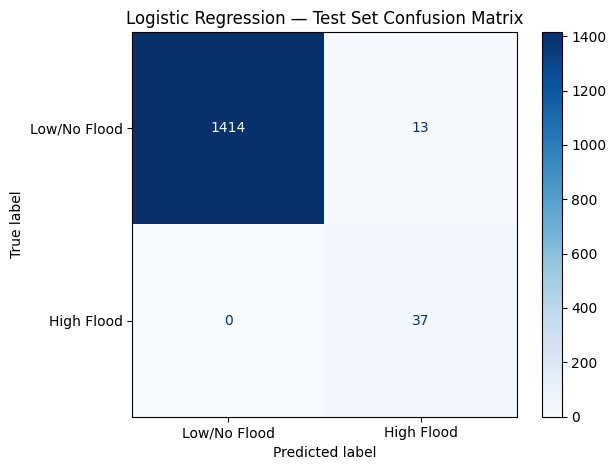

In [ ]:

# Step 10: Train and evaluate Logistic Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use only the three required environmental features
features = [
    "WaterLevel_m",
    "Rainfall_mm",
    "SoilMoisture_pct"
]

target = "FloodOccurrence"

# Sort observations chronologically
model_data = df_clean.sort_values("Date").copy()

# Select the date separating the earlier 80% from the later 20%
unique_dates = np.sort(model_data["Date"].unique())
split_index = int(len(unique_dates) * 0.80)
split_date = pd.Timestamp(unique_dates[split_index])

train_data = model_data[model_data["Date"] < split_date]
test_data = model_data[model_data["Date"] >= split_date]

X_train = train_data[features]
y_train = train_data[target].astype(int)

X_test = test_data[features]
y_test = test_data[target].astype(int)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Test period starts:", split_date.date())

print("\nFlood labels in training data:")
print(y_train.value_counts())

print("\nFlood labels in test data:")
print(y_test.value_counts())

# Check that training data contains both classes
if y_train.nunique() < 2:
    raise ValueError(
        "Training data contains only one class. "
        "We must revise the time split before training."
    )

# Build a pipeline to prevent scaling leakage
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train using the training period only
model.fit(X_train, y_train)

# Predict the test period
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nMODEL EVALUATION")
print("=" * 50)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Flood precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Flood recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("Flood F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

if y_test.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
else:
    print("ROC-AUC unavailable: test set contains only one class.")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Low/No Flood", "High Flood"],
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low/No Flood", "High Flood"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Step 12: Save the trained model and project data

import joblib
import json
from pathlib import Path

output_dir = Path("/content/flood_project_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the complete preprocessing + Logistic Regression pipeline
model_path = output_dir / "flood_logistic_regression.joblib"
joblib.dump(model, model_path)

# Save the feature names and class meanings for the app
metadata = {
    "project": "Flood Early-Warning System",
    "algorithm": "Logistic Regression",
    "features": [
        "WaterLevel_m",
        "Rainfall_mm",
        "SoilMoisture_pct"
    ],
    "target": "FloodOccurrence",
    "classes": {
        "0": "Low flood risk",
        "1": "High flood risk"
    },
    "dataset_region": "Metro Manila, Philippines",
    "warning": (
        "Prototype only. Not validated for operational flood warnings "
        "or for Rwanda."
    )
}

metadata_path = output_dir / "model_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Save the cleaned dataset for reproducibility
clean_data_path = output_dir / "flood_dataset_cleaned.csv"
df_clean.to_csv(clean_data_path, index=False)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)
print("Cleaned dataset saved:", clean_data_path)

print("\nSaved model file size:",
      round(model_path.stat().st_size / 1024, 2), "KB")
print("All project files are ready for the deployment stage.")


Model saved: /content/flood_project_outputs/flood_logistic_regression.joblib
Metadata saved: /content/flood_project_outputs/model_metadata.json
Cleaned dataset saved: /content/flood_project_outputs/flood_dataset_cleaned.csv

Saved model file size: 1.69 KB
All project files are ready for the deployment stage.


In [ ]:

from pathlib import Path
import shutil

project_dir = Path("/content/flood_app")
project_dir.mkdir(exist_ok=True)

# Copy the trained model and metadata
shutil.copy(
    "/content/flood_project_outputs/flood_logistic_regression.joblib",
    project_dir / "flood_logistic_regression.joblib"
)

shutil.copy(
    "/content/flood_project_outputs/model_metadata.json",
    project_dir / "model_metadata.json"
)

app_code = r'''
import json
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).parent

model = joblib.load(BASE_DIR / "flood_logistic_regression.joblib")

with open(BASE_DIR / "model_metadata.json", "r") as f:
    metadata = json.load(f)

st.set_page_config(
    page_title="Flood Early-Warning System",
    page_icon="🌧️",
    layout="centered"
)

st.title("🌧️ Flood Early-Warning System")
st.write(
    "Enter the environmental measurements below to estimate "
    "the flood-risk category."
)

st.warning(
    "Academic prototype only. This model uses historical data "
    "from Metro Manila, Philippines. It has not been validated "
    "for Rwanda or for real-world emergency warnings."
)

with st.form("flood_prediction_form"):
    water_level = st.number_input(
        "Water level (m)",
        min_value=0.0,
        max_value=100.0,
        value=1.0,
        step=0.1
    )

    rainfall = st.number_input(
        "Rainfall (mm)",
        min_value=0.0,
        max_value=1000.0,
        value=10.0,
        step=0.5
    )

    soil_moisture = st.number_input(
        "Soil moisture (%)",
        min_value=0.0,
        max_value=100.0,
        value=20.0,
        step=1.0
    )

    submitted = st.form_submit_button("Predict Flood Risk")

if submitted:
    input_data = pd.DataFrame([{
        "WaterLevel_m": water_level,
        "Rainfall_mm": rainfall,
        "SoilMoisture_pct": soil_moisture
    }])

    prediction = int(model.predict(input_data)[0])
    probability = float(model.predict_proba(input_data)[0][1])

    st.subheader("Prediction Result")

    st.metric(
        "Estimated High Flood probability",
        f"{probability:.1%}"
    )

    if prediction == 1:
        st.error("Predicted category: HIGH FLOOD RISK")
    else:
        st.success("Predicted category: LOW FLOOD RISK")

    st.caption(
        "This probability is a model estimate, not a calibrated "
        "real-world probability of a flood occurring."
    )
'''

app_path = project_dir / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("Application created:", app_path)
print("\nFiles in the application folder:")
for file in project_dir.iterdir():
    print("-", file.name)


Application created: /content/flood_app/app.py

Files in the application folder:
- flood_logistic_regression.joblib
- model_metadata.json
- app.py


In [ ]:

%pip -q install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 91.8 MB/s eta 0:00:00


In [ ]:

!streamlit run /content/flood_app/app.py \
    --server.port 8501 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &


In [ ]:

import requests
import time

url = "http://127.0.0.1:8501"

for attempt in range(10):
    try:
        response = requests.get(url, timeout=3)
        if response.status_code == 200:
            print("SUCCESS: Streamlit is running!")
            print("HTTP status:", response.status_code)
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("The app did not respond. Checking the server log...")

    with open("/content/streamlit.log", "r") as f:
        print(f.read()[-3000:])


SUCCESS: Streamlit is running!
HTTP status: 200


In [ ]:

%pip -q install pyngrok


In [ ]:

from pathlib import Path
import shutil
import zipfile

project_dir = Path("/content/flood_app")

# Add requirements with compatible ML library versions
requirements = """
streamlit
pandas
scikit-learn==1.6.1
joblib
"""

(project_dir / "requirements.txt").write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

# Add a short project description
readme = """
# Flood Early-Warning System

A machine-learning prototype that classifies flood risk as Low or High
using rainfall, water level, and soil moisture.

Algorithm: Logistic Regression
Data source: Metro Manila, Philippines (historical secondary data)

## Run locally
Install dependencies:
pip install -r requirements.txt

Run:
streamlit run app.py

## Limitation
This is an academic prototype and has not been validated for operational
flood warnings or for Rwanda.
"""

(project_dir / "README.md").write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

# Package only the files required for deployment
zip_path = shutil.make_archive(
    "/content/flood_early_warning_deployment",
    "zip",
    root_dir=project_dir
)

print("Deployment package created:", zip_path)

with zipfile.ZipFile(zip_path, "r") as archive:
    print("\nPackage contents:")
    for name in archive.namelist():
        print("-", name)


Deployment package created: /content/flood_early_warning_deployment.zip

Package contents:
- README.md
- flood_logistic_regression.joblib
- model_metadata.json
- requirements.txt
- app.py


In [ ]:

from google.colab import files

files.download("/content/flood_early_warning_deployment.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>